# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Ihya Alif Pramono
- NIM   : 241011401192
- Kelas : Reg B / ~~Reg C~~ *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [10]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 92   # 2 digit terakhir NIM 241011401192

In [3]:
# train_test_split (disalin dari materi)
# Fungsi ini membagi data menjadi data training dan data testing secara acak.
# Hasil acaknya selalu sama selama random_state sama.

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    # acak urutan index data, lalu ambil sebagian untuk testing dan sisanya untuk training
    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


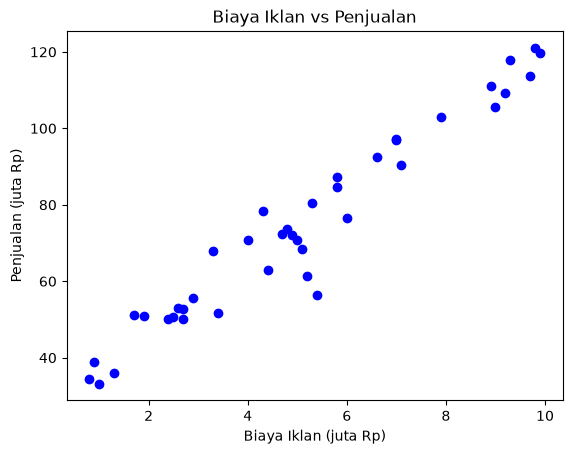

In [11]:
# Jawaban A1

# 1. Baca Ads_Data.csv, tampilkan 5 data pertama dan jumlah barisnya
ads = pd.read_csv('Ads_Data.csv')
print(ads.head())
print('Jumlah baris data:', len(ads))

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan)
#    X memakai [['BiayaIklan']] (dua kurung) supaya hasilnya 2 dimensi (n, 1)
X = ads[['BiayaIklan']].values
y = ads['Penjualan'].values
print('Shape X:', X.shape)
print('Shape y:', y.shape)

# 3. Scatter plot BiayaIklan vs Penjualan
plt.scatter(X, y, c='blue')
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [12]:
# Jawaban A2

# Bagi data: 80% training dan 20% testing (test_size=0.2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Tampilkan shape keempat data
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [13]:
# Jawaban A3

# Class LinearRegression dengan normal equation 
# beta = (X_b^T X_b)^-1 X_b^T y, dengan X_b = X yang ditambah kolom 1 untuk intercept
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


# 1. Latih model menggunakan data training
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# 2. Tampilkan intercept (b), koefisien (m), dan persamaan garis regresinya
b_ne = regressor.intercept_
m_ne = regressor.coefficients_[0]
print(f'Intercept (b) : {b_ne:.4f}')
print(f'Koefisien (m) : {m_ne:.4f}')
print(f'Persamaan     : y_hat = {b_ne:.4f} + {m_ne:.4f} * X')

# 3. Interpretasi nilai m ada di sel markdown di bawah

Intercept (b) : 27.7242
Koefisien (m) : 9.1831
Persamaan     : y_hat = 27.7242 + 9.1831 * X


**Jawaban A3 (interpretasi):**

Dari data training, garis regresinya adalah ŷ = 27.72 + 9.18X. Nilai m = 9.18 artinya setiap biaya iklan naik 1 juta rupiah, penjualan per bulan rata-rata naik sekitar 9.18 juta rupiah. Nilai b = 27.72 adalah perkiraan penjualan ketika biaya iklan 0. Angka b ini jangan dibaca terlalu harfiah, karena biaya iklan paling kecil di data adalah 0.8 juta, jadi kondisi "tanpa iklan sama sekali" tidak pernah benar-benar teramati.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [14]:
# Jawaban A4

# 1. Fungsi evaluasi regresi yang dibuat sendiri dengan NumPy
def mae(y_true, y_pred):
    # rata-rata selisih absolut
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    # rata-rata selisih kuadrat
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    # akar dari MSE, satuannya sama dengan y
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    # 1 - (jumlah kuadrat error / jumlah kuadrat total)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

# Prediksi untuk data training dan data testing
y_pred_train = regressor.predict(X_train)
y_pred_test = regressor.predict(X_test)

# 2. Tampilkan hasil training dan testing dalam satu tabel
hasil_eval = pd.DataFrame({
    'MAE':  [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    'MSE':  [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    'RMSE': [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    'R2':   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=['Training', 'Testing'])

# rata-rata penjualan data testing, dipakai sebagai pembanding RMSE di analisis
print('Rata-rata Penjualan data testing:', round(float(np.mean(y_test)), 2))
hasil_eval.round(4)

# 3. Penjelasan RMSE dan R2 ada di sel markdown di bawah

Rata-rata Penjualan data testing: 79.79


,MAE,MSE,RMSE,R2
Training,4.7778,40.6604,6.3766,0.9339
Testing,3.3909,17.7540,4.2135,0.9737


**Jawaban A4 (analisis):**

Pada data testing, RMSE-nya 4.21 (dalam juta rupiah). Artinya rata-rata prediksi penjualan dari model saya meleset sekitar 4.21 juta dari penjualan sebenarnya. Dibandingkan dengan rata-rata penjualan data testing yang 79.8 juta, meleset segitu hanya sekitar 5.3%, jadi tergolong kecil. Untuk R² testing yang 0.974, artinya sekitar 97.4% naik-turunnya penjualan bisa dijelaskan oleh biaya iklan, dan sisanya karena faktor lain yang tidak masuk ke model.

Menurut saya model ini sudah baik, apalagi hanya memakai satu variabel. Ada satu hal yang menarik: nilai di testing (RMSE 4.21, R² 0.974) malah lebih bagus daripada training (RMSE 6.38, R² 0.934), padahal biasanya kebalikannya. Saya kira ini kebetulan saja, karena data testing hanya 8 titik dan titik-titiknya kebetulan dekat dengan garis, bukan karena modelnya lebih pintar di data baru. Yang penting, performa di testing tidak turun dibanding training, jadi tidak ada tanda overfitting.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- learning rate = 0.001 ---
--- learning rate = 0.02 ---
--- learning rate = 0.1 ---

          Metode Learning rate  Intercept  Koefisien  MSE akhir (train)
 Normal equation             -  27.724221   9.183132          40.660436
Gradient descent         0.001  24.718143   9.663393          42.646827
Gradient descent          0.02  27.724221   9.183132          40.660436
Gradient descent           0.1        NaN        NaN                NaN

lr = 0.001: loss tetap valid sampai iterasi 5000 (dari 5928.3 menjadi 42.6468)
lr = 0.02: loss tetap valid sampai iterasi 5000 (dari 5928.3 menjadi 40.6604)
lr = 0.1: loss menjadi inf/NaN mulai iterasi ke-209 (divergen)
lambda_max = 63.58, jadi learning rate harus di bawah 0.0315


c:\Users\SR12\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\SR12\AppData\Local\Temp\ipykernel_26284\3572572693.py:25: RuntimeWarning: overflow encountered in square
  self.loss_history_.append(np.mean(error ** 2))   # simpan MSE tiap iterasi
C:\Users\SR12\AppData\Local\Temp\ipykernel_26284\3572572693.py:26: RuntimeWarning: overflow encountered in matmul
  gradient = (2 / len(y)) * X_b.T @ error
C:\Users\SR12\AppData\Local\Temp\ipykernel_26284\3572572693.py:27: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient       # update beta


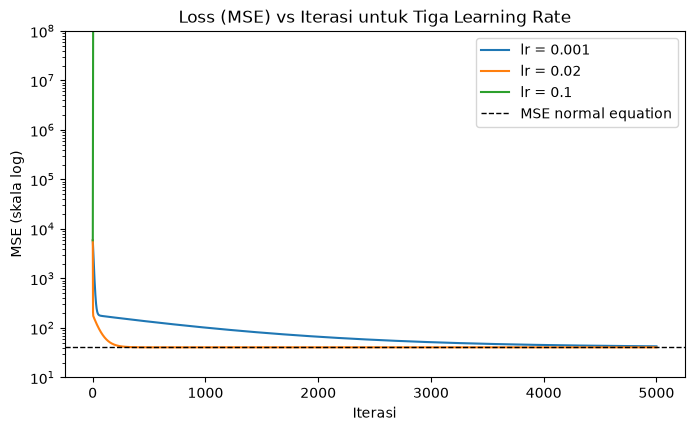

In [15]:
# Jawaban A5

# Class LinearRegressionGD: regresi linear yang dilatih dengan gradient descent
# loss = MSE, dan gradiennya = (2/n) * X_b^T (X_b beta - y)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])          # mulai dari beta = 0

        for _ in range(self.n_iterations):
            error = X_b @ beta - y
            self.loss_history_.append(np.mean(error ** 2))   # simpan MSE tiap iterasi
            gradient = (2 / len(y)) * X_b.T @ error
            beta = beta - self.learning_rate * gradient       # update beta

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


# 1. Latih model dengan n_iterations=5000 untuk 3 learning rate
#    (warning overflow pada lr 0.1 memang diharapkan, penjelasannya ada di sel analisis)
learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
for lr in learning_rates:
    print(f'--- learning rate = {lr} ---')
    models_gd[lr] = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)

# 2. Intercept dan koefisien akhir tiap learning rate, dibandingkan dengan normal equation (A3)
baris = [{'Metode': 'Normal equation', 'Learning rate': '-',
          'Intercept': b_ne, 'Koefisien': m_ne,
          'MSE akhir (train)': mse(y_train, y_pred_train)}]
for lr, mdl in models_gd.items():
    baris.append({'Metode': 'Gradient descent', 'Learning rate': lr,
                  'Intercept': mdl.intercept_, 'Koefisien': mdl.coefficients_[0],
                  'MSE akhir (train)': mdl.loss_history_[-1]})
print()
print(pd.DataFrame(baris).to_string(index=False))

# Cek di iterasi berapa loss mulai tidak valid (inf / NaN)
print()
for lr, mdl in models_gd.items():
    loss_gd = np.array(mdl.loss_history_)
    if np.all(np.isfinite(loss_gd)):
        print(f'lr = {lr}: loss tetap valid sampai iterasi 5000 (dari {loss_gd[0]:.1f} menjadi {loss_gd[-1]:.4f})')
    else:
        print(f'lr = {lr}: loss menjadi inf/NaN mulai iterasi ke-{int(np.argmax(~np.isfinite(loss_gd))) + 1} (divergen)')

# Batas learning rate agar gradient descent stabil: lr < 2 / lambda_max,
# dengan lambda_max = eigenvalue terbesar dari (2/n) X_b^T X_b
X_b_train = np.c_[np.ones(len(X_train)), X_train]
lambda_max = np.max(np.linalg.eigvalsh((2 / len(X_train)) * X_b_train.T @ X_b_train))
print(f'lambda_max = {lambda_max:.2f}, jadi learning rate harus di bawah {2 / lambda_max:.4f}')

# 3. Grafik loss (MSE) vs iterasi untuk ketiga learning rate (skala log)
plt.figure(figsize=(8, 4.5))
for lr, mdl in models_gd.items():
    loss_plot = np.array(mdl.loss_history_, dtype=float)
    loss_plot[~np.isfinite(loss_plot)] = np.nan      # nilai inf/NaN tidak bisa digambar, garis berhenti di situ
    plt.plot(np.arange(1, 5001), loss_plot, label=f'lr = {lr}')
plt.ylim(10, 1e8)                                     # batasi sumbu y supaya lr 0.001 dan 0.02 tetap terlihat
plt.axhline(mse(y_train, y_pred_train), color='k', linestyle='--', linewidth=1, label='MSE normal equation')
plt.yscale('log')
plt.title('Loss (MSE) vs Iterasi untuk Tiga Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('MSE (skala log)')
plt.legend()
plt.show()

# 4. Penjelasan tiap learning rate ada di sel markdown di bawah

**Jawaban A5 (analisis):**

Sebagai pembanding, normal equation (A3) memberi intercept 27.7242, koefisien 9.1831, dan MSE training 40.660.

**lr = 0.001 (terlalu lambat).** Setelah 5000 iterasi hasilnya masih belum sampai: intercept 24.7181, koefisien 9.6634, MSE 42.647, masih di atas 40.660. Di grafik, garis biru turun sangat landai dan belum menyentuh garis putus-putus. Langkah per iterasinya terlalu kecil, jadi butuh iterasi jauh lebih banyak untuk sampai.

**lr = 0.02 (pas).** Hasilnya sama dengan normal equation sampai empat desimal: intercept 27.7242, koefisien 9.1831, MSE 40.660. Di grafik, garis oranye turun cepat lalu mendatar tepat di garis putus-putus, jadi sudah konvergen.

**lr = 0.1 (divergen).** Loss tidak turun, malah membesar terus lalu menjadi inf/NaN mulai iterasi ke-209, sehingga intercept dan koefisien akhirnya NaN. Penyebabnya, langkah update terlalu besar: parameter melompati titik minimum ke sisi seberangnya, dan di sisi seberang errornya malah lebih besar lagi. Lompatan berikutnya makin jauh, sehingga errornya meledak. Secara teori, gradient descent untuk MSE ini hanya stabil kalau learning rate di bawah 2/λmax = 2/63.58 = 0.0315. Jadi 0.02 aman, sedangkan 0.1 sudah melewati batas.

Tentang `RuntimeWarning: overflow`: artinya angka yang dihitung sudah melebihi batas terbesar yang bisa disimpan float64 (sekitar 10^308). Ini terjadi karena loss meledak pada lr 0.1. Jadi warning itu bukan bug di kode, tapi tanda bahwa gradient descent-nya divergen.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

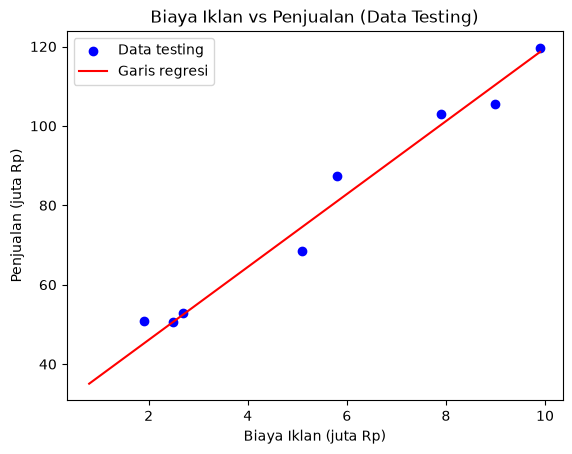

Biaya iklan  4.5 juta -> prediksi penjualan = 69.05 juta
Biaya iklan  7.0 juta -> prediksi penjualan = 92.01 juta
Biaya iklan 12.0 juta -> prediksi penjualan = 137.92 juta

Rentang BiayaIklan di data: 0.8 sampai 9.9 juta


In [16]:
# Jawaban A6

# 1. Scatter data testing beserta garis regresi dari model di A3
x_garis = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.scatter(X_test, y_test, c='blue', label='Data testing')
plt.plot(x_garis, regressor.predict(x_garis), c='r', label='Garis regresi')
plt.title('Biaya Iklan vs Penjualan (Data Testing)')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5, 7, dan 12 juta
biaya_baru = np.array([[4.5], [7], [12]])
prediksi = regressor.predict(biaya_baru)
for biaya, p in zip(biaya_baru[:, 0], prediksi):
    print(f'Biaya iklan {biaya:>4} juta -> prediksi penjualan = {p:.2f} juta')

# 3. Untuk soal ekstrapolasi, bandingkan 12 juta dengan rentang biaya iklan di data
print(f'\nRentang BiayaIklan di data: {X.min()} sampai {X.max()} juta')

**Jawaban A6 (analisis):**

Hasil prediksinya: biaya iklan 4.5 juta menghasilkan penjualan sekitar 69.05 juta, 7 juta sekitar 92.01 juta, dan 12 juta sekitar 137.92 juta.

Prediksi untuk 4.5 dan 7 juta masih berada di dalam rentang data (0.8 sampai 9.9 juta), jadi cukup bisa dipercaya, dengan perkiraan meleset sekitar RMSE, yaitu ±4.2 juta. Lain halnya dengan 12 juta. Angka itu sudah di luar rentang data sehingga disebut ekstrapolasi, dan menurut saya hasil 137.92 juta kurang bisa dipercaya karena tiga alasan. Pertama, model hanya pernah melihat data sampai biaya iklan 9.9 juta, jadi tidak ada bukti bahwa hubungannya tetap lurus setelah itu. Kedua, di dunia nyata iklan biasanya ada titik jenuhnya: tambahan biaya iklan memberi tambahan penjualan yang makin kecil, sehingga garis lurus bisa terlalu optimis. Ketiga, makin jauh dari data, makin besar ketidakpastian prediksinya. Jadi angka 12 juta itu cukup dipakai sebagai gambaran kasar saja.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Bukan Spam (0): 35
Jumlah Spam (1)      : 25

Shape X: (60, 2) | Shape y: (60,)


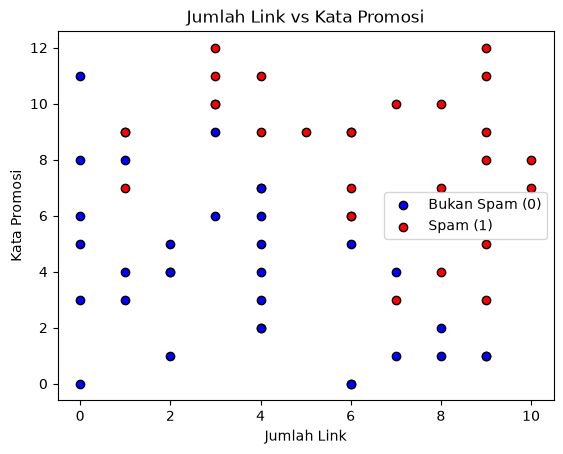

In [17]:
# Jawaban B1

# 1. Baca Email_Data.csv, tampilkan 5 data pertama, dan hitung jumlah Spam / Bukan Spam
email = pd.read_csv('Email_Data.csv')
print(email.head())
print()
print('Jumlah Bukan Spam (0):', int((email['Spam'] == 0).sum()))
print('Jumlah Spam (1)      :', int((email['Spam'] == 1).sum()))

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = email[['JumlahLink', 'KataPromo']].values
y_email = email['Spam'].values
print('\nShape X:', X_email.shape, '| Shape y:', y_email.shape)

# 3. Scatter plot JumlahLink vs KataPromo, warna berbeda untuk tiap kelas
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], c='blue', edgecolors='k', label='Bukan Spam (0)')
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], c='red', edgecolors='k', label='Spam (1)')
plt.title('Jumlah Link vs Kata Promosi')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promosi')
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train: (45, 2) | Xe_test: (15, 2)
Intercept (b)            : -8.9171
Koefisien m1 (JumlahLink): 0.7964
Koefisien m2 (KataPromo) : 0.7573
P(Spam) = sigmoid(-8.9171 + 0.7964 * JumlahLink + 0.7573 * KataPromo)
Log loss iterasi     1: 0.6931
Log loss iterasi   100: 0.5634
Log loss iterasi  1000: 0.3595
Log loss iterasi  5000: 0.3235
Log loss iterasi 10000: 0.3223


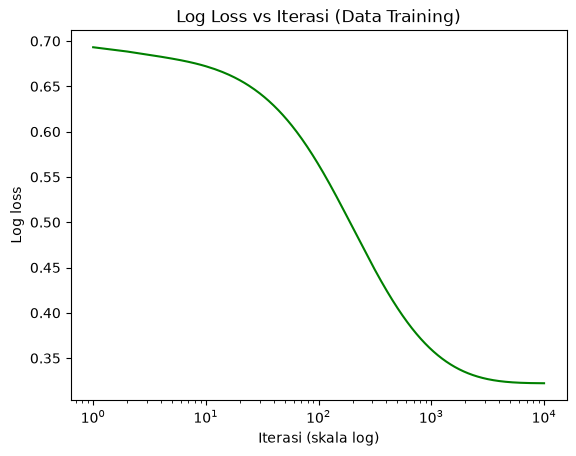

In [18]:
# Jawaban B2

# Class LogisticRegression dengan gradient descent (disalin dari materi)
# P(spam) = sigmoid(b + m1*x1 + m2*x2), dan loss-nya adalah log loss
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)      # hindari log(0)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


# 1. Bagi data: 75% training dan 25% testing (test_size=0.25)
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
print('Xe_train:', Xe_train.shape, '| Xe_test:', Xe_test.shape)

# 2. Latih model dengan learning_rate=0.1 dan n_iterations=10000
classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(Xe_train, ye_train)

# 3. Tampilkan intercept, koefisien, dan persamaannya
b_lr = classifier.intercept_
m1_lr, m2_lr = classifier.coefficients_
print(f'Intercept (b)            : {b_lr:.4f}')
print(f'Koefisien m1 (JumlahLink): {m1_lr:.4f}')
print(f'Koefisien m2 (KataPromo) : {m2_lr:.4f}')
print(f'P(Spam) = sigmoid({b_lr:.4f} + {m1_lr:.4f} * JumlahLink + {m2_lr:.4f} * KataPromo)')

# 4. Grafik log loss vs iterasi, dan nilai loss di beberapa iterasi untuk melihat apakah sudah stabil
loss = np.array(classifier.loss_history_)
for it in [1, 100, 1000, 5000, 10000]:
    print(f'Log loss iterasi {it:>5}: {loss[it - 1]:.4f}')

plt.plot(np.arange(1, len(loss) + 1), loss, c='g')
plt.xscale('log')
plt.title('Log Loss vs Iterasi (Data Training)')
plt.xlabel('Iterasi (skala log)')
plt.ylabel('Log loss')
plt.show()

**Jawaban B2 (analisis):**

Persamaan modelnya: P(Spam) = σ(-8.9171 + 0.7964 · JumlahLink + 0.7573 · KataPromo). Kedua koefisien positif, jadi makin banyak link dan makin banyak kata promosi, peluang email dianggap spam makin besar. Sebagai gambaran, setiap tambahan 1 link mengalikan odds spam sekitar 2.22 kali (e^0.796), dan setiap tambahan 1 kata promosi sekitar 2.13 kali.

Untuk grafik log loss, nilai awalnya 0.6931 (ini ln 2, karena awalnya semua parameter 0 sehingga P = 0.5). Setelah itu turun cepat ke 0.3595 di iterasi 1000, lalu 0.3235 di iterasi 5000 dan 0.3223 di iterasi 10000. Dari iterasi 5000 sampai 10000 loss hanya turun 0.0012, dan di grafik kurvanya sudah mendatar di sisi kanan. Jadi loss sudah turun dan stabil. Loss tidak sampai mendekati 0 karena ada email spam dan bukan spam yang posisinya bercampur, sehingga tidak bisa dipisahkan sempurna oleh satu garis lurus.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [19]:
# Jawaban B3

# accuracy_score dan confusion_matrix (dari materi)
# confusion_matrix: [[TN, FP],
#                    [FN, TP]]
def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([[tn, fp],
                     [fn, tp]])

# precision, recall, dan f1 dibuat sendiri (tambahan dari soal)
def precision_score(y_true, y_pred):
    # TP / (TP + FP): dari semua yang diprediksi spam, berapa yang benar-benar spam
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0   # kalau tidak ada prediksi spam, precision dianggap 0

def recall_score(y_true, y_pred):
    # TP / (TP + FN): dari semua spam yang sebenarnya, berapa yang berhasil ditangkap
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    # rata-rata harmonik precision dan recall
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

# 1. Evaluasi pada data testing (threshold default 0.5)
ye_pred = classifier.predict(Xe_test)
cm = confusion_matrix(ye_test, ye_pred)

print('Jumlah data testing:', len(ye_test))
print(f'Accuracy : {accuracy_score(ye_test, ye_pred):.4f}')
print(f'Precision: {precision_score(ye_test, ye_pred):.4f}')
print(f'Recall   : {recall_score(ye_test, ye_pred):.4f}')
print(f'F1-score : {f1_score(ye_test, ye_pred):.4f}')
print('\nConfusion matrix:')
print(pd.DataFrame(cm, index=['Aktual Bukan Spam', 'Aktual Spam'],
                   columns=['Prediksi Bukan Spam', 'Prediksi Spam']))

# 2. Penjelasan FP dan FN ada di sel markdown di bawah

Jumlah data testing: 15
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Confusion matrix:
                   Prediksi Bukan Spam  Prediksi Spam
Aktual Bukan Spam                    9              0
Aktual Spam                          0              6


**Jawaban B3 (analisis):**

Pada data testing (15 email, threshold 0.5), hasilnya: accuracy 1.000, precision 1.000, recall 1.000, dan F1 1.000. Confusion matrix-nya TN = 9, FP = 0, FN = 0, TP = 6, jadi seluruh 15 email tertebak benar. Hasil sempurna ini sebaiknya tidak dibaca berlebihan, karena data testing-nya hanya 15 email.

FP (false positive) adalah email yang sebenarnya bukan spam tetapi ditebak spam, sehingga masuk folder spam. FN (false negative) adalah email yang sebenarnya spam tetapi ditebak bukan spam, sehingga lolos ke inbox. Di hasil saya, keduanya 0.

Menurut saya FP lebih merugikan pengguna. Kalau email penting seperti info kuliah, tagihan, atau balasan lamaran kerja masuk folder spam, pengguna bisa tidak sadar dan ketinggalan informasi. Kalau FN, yang terjadi hanya ada satu email spam di inbox, dan itu tinggal dihapus.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-8.9171 + 0.7964 * x1) / 0.7573
                   x2 = 11.7751 + (-1.0516) * x1


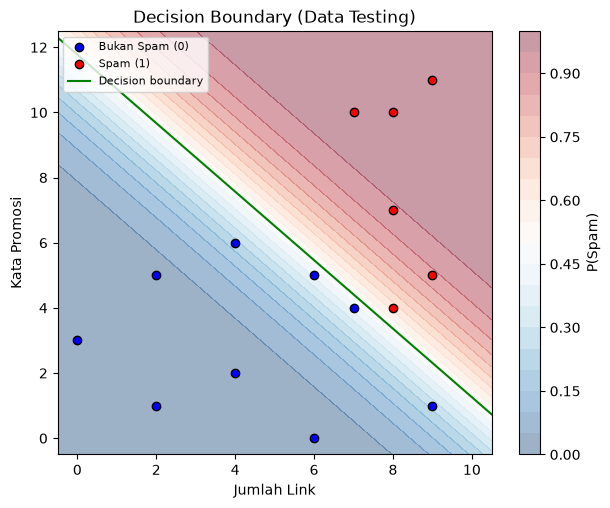

Data testing yang salah klasifikasi: 0 dari 15


In [20]:
# Jawaban B4

# 1. Persamaan decision boundary (garis saat probabilitas = 0.5)
#    b + m1*x1 + m2*x2 = 0  ->  x2 = -(b + m1*x1) / m2
x1_line = np.linspace(-0.5, 10.5, 100)
x2_line = -(b_lr + m1_lr * x1_line) / m2_lr
print(f'Decision boundary: x2 = -({b_lr:.4f} + {m1_lr:.4f} * x1) / {m2_lr:.4f}')
print(f'                   x2 = {-b_lr / m2_lr:.4f} + ({-m1_lr / m2_lr:.4f}) * x1')

# 2. Visualisasi data testing, background = probabilitas spam, garis hijau = decision boundary
xx1, xx2 = np.meshgrid(np.linspace(-0.5, 10.5, 200), np.linspace(-0.5, 12.5, 200))
proba_grid = classifier.predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

plt.figure(figsize=(7, 5.5))
cs = plt.contourf(xx1, xx2, proba_grid, levels=20, cmap='RdBu_r', alpha=0.4)
plt.colorbar(cs, label='P(Spam)')
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], c='blue', edgecolors='k', label='Bukan Spam (0)')
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], c='red', edgecolors='k', label='Spam (1)')
plt.plot(x1_line, x2_line, c='g', label='Decision boundary')

# 3. Beri tanda (lingkaran hitam besar) pada data testing yang salah diklasifikasikan
salah = ye_pred != ye_test
if salah.any():
    plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=260, facecolors='none', edgecolors='k',
                linewidths=2, label='Salah klasifikasi')

plt.xlim(-0.5, 10.5)
plt.ylim(-0.5, 12.5)
plt.title('Decision Boundary (Data Testing)')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promosi')
plt.legend(loc='upper left', fontsize=8)
plt.show()

# Daftar data testing yang salah diklasifikasikan
print(f'Data testing yang salah klasifikasi: {int(salah.sum())} dari {len(ye_test)}')
if salah.any():
    print(pd.DataFrame({
        'JumlahLink': Xe_test[salah, 0],
        'KataPromo': Xe_test[salah, 1],
        'Label asli': ye_test[salah],
        'Prediksi': ye_pred[salah],
        'P(Spam)': classifier.predict_proba(Xe_test[salah]).round(4),
    }).to_string(index=False))

**Jawaban B4 (analisis):**

Persamaan decision boundary-nya x2 = -(-8.9171 + 0.7964 · x1) / 0.7573, atau kalau disederhanakan x2 = 11.775 − 1.052 · x1, dengan x1 = JumlahLink dan x2 = KataPromo. Garisnya turun ke kanan: titik di atas garis diprediksi Spam dan titik di bawahnya diprediksi Bukan Spam. Makin jauh dari garis, warna latar makin pekat, artinya probabilitasnya makin dekat ke 0 atau 1.

Dari grafik, tidak ada data testing yang salah diklasifikasikan (0 dari 15), jadi memang tidak ada titik yang saya beri lingkaran hitam. Semua titik merah (Spam) ada di atas garis dan semua titik biru (Bukan Spam) ada di bawah garis. Titik yang paling rawan salah tetap yang dekat garis, tempat warna latar hampir putih. Di dataset lengkap juga ada kombinasi yang muncul dua kali dengan label berbeda, yaitu (1, 9), (3, 10), (6, 6). Untuk titik seperti itu, model apa pun yang hanya memakai dua fitur ini pasti salah di salah satunya kalau keduanya masuk testing. Pada pembagian data saya, hal itu kebetulan tidak terjadi.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [21]:
# Jawaban B5

# 1. Prediksi dengan threshold 0.3, 0.5, dan 0.7 memakai predict_proba
proba_test = classifier.predict_proba(Xe_test)

# 2. Hitung confusion matrix, precision, dan recall untuk tiap threshold, simpan dalam satu tabel
baris = []
for th in [0.3, 0.5, 0.7]:
    pred_th = (proba_test >= th).astype(int)          # spam kalau probabilitas >= threshold
    tn, fp, fn, tp = confusion_matrix(ye_test, pred_th).ravel()
    baris.append({'Threshold': th, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                  'Precision': precision_score(ye_test, pred_th),
                  'Recall': recall_score(ye_test, pred_th)})

tabel_threshold = pd.DataFrame(baris).set_index('Threshold')
tabel_threshold.round(4)

# 3. Pengaruh threshold dan threshold pilihan dijelaskan di sel markdown di bawah

,TN,FP,FN,TP,Precision,Recall
Threshold,,,,,,
0.3,7,2,0,6,0.75,1.0000
0.5,9,0,0,6,1.00,1.0000
0.7,9,0,1,5,1.00,0.8333


**Jawaban B5 (analisis):**

Hasil di tabel B5 untuk threshold 0.3, 0.5, dan 0.7: FP = 2, 0, 0; FN = 0, 0, 1; precision = 0.750, 1.000, 1.000; recall = 1.000, 1.000, 0.833.

Kalau threshold dinaikkan, model jadi lebih pelit melabeli email sebagai spam karena harus lebih yakin dulu. Akibatnya FP berkurang dan precision naik (dari 0.750 di threshold 0.3 menjadi 1.000 di 0.5), tetapi ada spam yang lolos sehingga FN naik dan recall turun (di threshold 0.7 recall menjadi 0.833 karena 1 spam lolos). Sebaliknya, kalau threshold diturunkan, lebih banyak email dicap spam: recall naik, tapi FP bertambah dan precision turun (di threshold 0.3 ada 2 email asli yang salah dicap spam).

Dari jawaban B3, saya menilai FP lebih merugikan, jadi yang saya cari adalah precision setinggi mungkin tanpa membuat recall jatuh. Threshold 0.5 dan 0.7 sama-sama punya precision 1.000, tetapi di 0.7 sudah ada 1 spam yang lolos, sedangkan di 0.5 tidak ada. Karena itu saya memilih **threshold 0.5**. Perlu diingat bahwa pilihan ini hanya berdasarkan 15 email testing, jadi dengan data yang lebih banyak hasilnya bisa saja berbeda.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [22]:
# Jawaban B6

# Threshold yang saya pilih dari Soal B5 (alasannya ada di jawaban B5)
THRESHOLD_PILIHAN = 0.5

# Data 4 email baru dari soal
email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})

# Hitung probabilitas spam, lalu tentukan kelasnya dengan threshold pilihan
proba_baru = classifier.predict_proba(email_baru[['JumlahLink', 'KataPromo']].values)
email_baru['P(Spam)'] = proba_baru.round(4)
email_baru['Prediksi'] = np.where(proba_baru >= THRESHOLD_PILIHAN, 'Spam', 'Bukan Spam')
print(f'Threshold yang dipakai: {THRESHOLD_PILIHAN}')
email_baru

Threshold yang dipakai: 0.5


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0014,Bukan Spam
1,E2,5,6,0.4034,Bukan Spam
2,E3,9,10,0.9971,Spam
3,E4,2,11,0.7322,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Walaupun namanya "regression", Logistic Regression dipakai untuk klasifikasi karena yang ingin ditebak adalah kelas (misalnya Spam atau Bukan Spam), bukan angka biasa. Di dalamnya memang masih ada hitungan linear z = b + m1·x1 + m2·x2 seperti regresi linear. Peran fungsi sigmoid adalah mengubah z, yang nilainya bisa berapa saja, menjadi angka antara 0 dan 1 sehingga bisa dibaca sebagai probabilitas kelas 1. Setelah itu probabilitasnya dibandingkan dengan threshold (biasanya 0.5) untuk menentukan kelas akhirnya.

**Jawaban C2:**

Normal equation menghitung koefisien langsung dalam sekali hitung dengan rumus β = (XᵀX)⁻¹Xᵀy, jadi hasilnya pasti dan tidak butuh learning rate. Kekurangannya, ia butuh invers matriks yang berat kalau fiturnya banyak dan bisa gagal kalau matriksnya singular. Gradient descent mencari koefisien sedikit demi sedikit dengan mengikuti arah turunnya loss, jadi harus memilih learning rate dan jumlah iterasi, dan hasilnya hanya mendekati solusi. Gradient descent sebaiknya dipakai kalau data atau fiturnya sangat banyak, atau kalau modelnya tidak punya rumus langsung seperti Logistic Regression. Di tugas ini keduanya setara, karena dengan learning rate 0.02 hasilnya sama dengan normal equation.

**Jawaban C3:**

Model sudah pernah melihat data training saat belajar, jadi skor di sana bisa terlalu bagus dan tidak menggambarkan kemampuan sebenarnya. Data testing belum pernah dilihat model, sehingga lebih jujur untuk mengukur seberapa baik model bekerja pada data baru. Overfitting adalah kondisi saat model terlalu menghafal data training termasuk noise-nya, sehingga bagus di training tetapi jelek di data baru. Di tugas ini R² training 0.934 dan testing 0.974, jadi testing tidak lebih buruk dan tidak ada tanda overfitting.

**Jawaban C4:**

Linear Regression memprediksi angka kontinu, jadi wajar kalau kesalahannya diukur dari selisih antara angka prediksi dan angka asli, yaitu dengan MSE. Logistic Regression menghasilkan probabilitas antara 0 dan 1, sedangkan targetnya hanya 0 atau 1, sehingga lebih cocok memakai log loss. Log loss memberi hukuman sangat besar kalau model yakin tapi salah, misalnya memberi P mendekati 0 padahal kelas aslinya 1. Bersama sigmoid, log loss juga berbentuk cekung (konveks) sehingga gradient descent bisa menemukan minimum yang baik. Kalau MSE dipakai bersama sigmoid, gradiennya jadi sangat kecil saat prediksi salah dan belajarnya lambat.

**Jawaban C5:**

Karena `random_state` saya adalah 92, sedangkan teman saya memakai dua digit terakhir NIM mereka sendiri. `random_state` yang berbeda membuat pembagian data training dan testing berbeda, sehingga koefisien yang dipelajari model dan skor testing-nya ikut berbeda. Pengaruhnya besar di tugas ini karena datanya kecil: data testing hanya 8 titik (regresi) dan 15 titik (klasifikasi), jadi satu email salah tebak saja mengubah akurasi sekitar 6.7%. Jadi walaupun dataset dan algoritmanya sama, angkanya bisa berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [24]:
# Jawaban Bonus
# scikit-learn hanya dipakai di sel ini untuk membandingkan hasil
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# 1. Linear Regression: latih dengan data training yang sama seperti Bagian A
sk_lin = SkLinearRegression().fit(X_train, y_train)
print('LINEAR REGRESSION')
print(f'Implementasi sendiri: intercept = {b_ne:.6f}, koefisien = {m_ne:.6f}')
print(f'scikit-learn        : intercept = {sk_lin.intercept_:.6f}, koefisien = {sk_lin.coef_[0]:.6f}')
print(f'R2 testing sendiri = {r2_score(y_test, y_pred_test):.6f} | sklearn = {sk_lin.score(X_test, y_test):.6f}')

# 2. Logistic Regression: latih dengan data training yang sama seperti Soal B2
#    default sklearn memakai regularisasi L2 dengan C=1.0
#    C=1e6 (sangat besar) membuat regularisasinya hampir hilang
sk_log_default = SkLogisticRegression(max_iter=10000).fit(Xe_train, ye_train)
sk_log_besar_C = SkLogisticRegression(C=1e6, max_iter=10000).fit(Xe_train, ye_train)

tabel_log = pd.DataFrame({
    'Intercept': [b_lr, sk_log_default.intercept_[0], sk_log_besar_C.intercept_[0]],
    'm1 (JumlahLink)': [m1_lr, sk_log_default.coef_[0][0], sk_log_besar_C.coef_[0][0]],
    'm2 (KataPromo)': [m2_lr, sk_log_default.coef_[0][1], sk_log_besar_C.coef_[0][1]],
    'Accuracy test': [accuracy_score(ye_test, ye_pred),
                      accuracy_score(ye_test, sk_log_default.predict(Xe_test)),
                      accuracy_score(ye_test, sk_log_besar_C.predict(Xe_test))],
}, index=['Implementasi sendiri', 'sklearn (default, C=1)', 'sklearn (C=1e6)'])
print('\nLOGISTIC REGRESSION')
tabel_log.round(4)

LINEAR REGRESSION
Implementasi sendiri: intercept = 27.724221, koefisien = 9.183132
scikit-learn        : intercept = 27.724221, koefisien = 9.183132
R2 testing sendiri = 0.973693 | sklearn = 0.973693

LOGISTIC REGRESSION


,Intercept,m1 (JumlahLink),m2 (KataPromo),Accuracy test
Implementasi sendiri,-8.9171,0.7964,0.7573,1.0
"sklearn (default, C=1)",-8.2595,0.7299,0.7038,1.0
sklearn (C=1e6),-9.1110,0.8145,0.7730,1.0


**Jawaban Bonus (analisis):**

Untuk Linear Regression, hasil scikit-learn sama persis dengan implementasi saya: intercept 27.724221 dan koefisien 9.183132, dan R² testing-nya juga sama. Ini wajar karena keduanya menyelesaikan masalah least squares yang sama.

Untuk Logistic Regression, koefisiennya berbeda:

| | Intercept | m1 (JumlahLink) | m2 (KataPromo) | Accuracy test |
|---|---|---|---|---|
| Implementasi sendiri | -8.9171 | 0.7964 | 0.7573 | 1.000 |
| sklearn default (C = 1) | -8.2595 | 0.7299 | 0.7038 | 1.000 |
| sklearn (C = 1e6) | -9.1110 | 0.8145 | 0.7730 | 1.000 |

Penyebab utamanya, `LogisticRegression` di scikit-learn secara default memakai regularisasi L2 dengan `C = 1.0`, yaitu memberi penalti pada koefisien yang besar sehingga nilainya mengerut. Itu sebabnya koefisien sklearn default (0.7299 dan 0.7038) lebih kecil dibanding punya saya (0.7964 dan 0.7573), karena implementasi saya tidak memakai regularisasi. Kalau `C` dibuat sangat besar (1e6), regularisasinya hampir hilang dan koefisiennya mendekati milik saya (0.8145 dan 0.7730). Sisa selisih kecilnya karena cara mencarinya berbeda: saya memakai gradient descent 10000 iterasi (loss masih turun pelan), sedangkan sklearn memakai solver lbfgs yang jalan sampai konvergen. Meski koefisiennya berbeda, akurasi testing keduanya sama (1.000) karena decision boundary-nya hanya bergeser sedikit.